John S. Anvik, 2025  
University of Lethbridge Student ID: 001224816

Import Packages

In [1]:
# install.packages("tidymodels")
# install.packages('rlang')
# install.packages("ranger")
# install.packages("rpart.plot")
# install.packages("vip")
library(tidyverse)
library(tidymodels)
library(rpart.plot) # for plotting decision tree
library(vip) # for ranking feature importance
# library(ranger) # engine for random forest

# set random seed
set.seed(42)

Warning message:
"package 'tidyverse' was built under R version 4.4.3"
Warning message:
"package 'ggplot2' was built under R version 4.4.3"
Warning message:
"package 'tibble' was built under R version 4.4.3"
Warning message:
"package 'tidyr' was built under R version 4.4.3"
Warning message:
"package 'readr' was built under R version 4.4.3"
Warning message:
"package 'purrr' was built under R version 4.4.3"
Warning message:
"package 'dplyr' was built under R version 4.4.3"
Warning message:
"package 'forcats' was built under R version 4.4.3"
Warning message:
"package 'lubridate' was built under R version 4.4.3"
── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.1.4     ✔ readr     2.1.5
✔ forcats   1.0.0     ✔ stringr   1.5.1
✔ ggplot2   4.0.0     ✔ tibble    3.3.0
✔ lubridate 1.9.4     ✔ tidyr     1.3.1
✔ purrr     1.1.0     
── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()

Load data

In [2]:
data <- read_csv("../data/song_type_frequency.csv")

Rows: 709 Columns: 73
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
dbl  (72): UST, M1_song_number, time_since_M1_1_last_song, time_rel_sunrise,...
dttm  (1): DateTime

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.


In [3]:
# Set data types and select input columns
data <- data %>% 
    mutate(across(contains("UST"), ~ as.factor(.x)),
    across(contains("ust"), ~ as.factor(.x)), 
        does_it_match = as.factor(does_it_match),
        number_of_matches = as.integer(number_of_matches)) %>%
    select(
        "UST",
        # "time_since_M1_1_last_song",
        contains("n_ust_")
    )  %>%
    drop_na() # drop any row containing at least one NA value

In [4]:
glimpse(data)

Rows: 709
Columns: 67
$ UST         <fct> 10, 10, 3, 8, 9, 13, 29, 10, 5, 16, 13, 10, 21, 5, 8, 10, …
$ n_ust_1     <fct> 10, 0, 0, 1, 0, 0, 1, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 1, …
$ n_ust_3     <fct> 14, 0, 0, 2, 0, 1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, …
$ n_ust_4     <fct> 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0…
$ n_ust_5     <fct> 13, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, …
$ n_ust_6     <fct> 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0…
$ n_ust_7     <fct> 10, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, …
$ n_ust_8     <fct> 23, 0, 0, 0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, …
$ n_ust_9     <fct> 17, 0, 0, 1, 0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, …
$ n_ust_10    <fct> 21, 2, 1, 0, 0, 0, 0, 1, 1, 1, 0, 0, 0, 0, 0, 1, 1, 0, 0, …
$ n_ust_11    <fct> 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0…
$ n_ust_12    <fct> 5, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0…
$ n_ust_13    <fct

In [5]:

# train test split
train_test_split <- initial_split(data, prop = 0.7, strata=UST)

train_data <- train_test_split %>% training()
test_data <- train_test_split %>% testing()

# In training data, how many song type matches?
train_data %>%
    group_by(UST) %>%
    summarize(n = n()) %>%
    mutate(percent = 100*n/nrow(train_data)) %>%
    arrange(desc(percent))

# use v-fold cross validation to assess model accuracy
v <- 5
train_vfold <- vfold_cv(train_data, v=v, strata = UST)

UST,n,percent
<fct>,<int>,<dbl>
9,83,16.8016194
3,72,14.5748988
8,71,14.3724696
10,62,12.5506073
29,54,10.9311741
13,44,8.9068826
5,31,6.2753036
21,31,6.2753036
17,22,4.4534413


In [6]:
# Data preprocessing using a recipe
recipe <- recipe(UST ~ ., data = train_data)
    # step_scale(all_numeric()) %>% # scale all numeric predictors
    # step_center(all_numeric()) # center all numeric predictors

In [7]:
# Create model specification
model_tuning_spec <- rand_forest(mtry = tune(), trees = 1000, min_n=tune()) %>%
    set_engine("ranger", importance = "impurity") %>% # importance = impurity measures feature importance (using gini impurity reduction), used for vip() later
    set_mode("classification")

In [8]:
tune_grid <- tidyr::crossing(
    mtry = c(10, 20, 30, 40, 50, 60), # The number of variables randomly sampled as candidates at each split
    min_n = c(2, 5, 10, 15, 20) # Minimum number of data points in a node required for a split
)
eval_metrics <- metric_set(accuracy, precision, recall)

model_tuning <- workflow() %>%
    add_recipe(recipe) %>%
    add_model(model_tuning_spec) %>%

        tune_grid(resamples = train_vfold, grid=tune_grid, metrics = eval_metrics) # for v-fold cross validation, tuning k parameter
        # fit(data = train_data) # to train on whole train set with no validation set

model_tuning

→ A | warning: Dropped unused factor level(s) in dependent variable: 115, 118.

There were issues with some computations   A: x1

There were issues with some computations   A: x3

There were issues with some computations   A: x6

There were issues with some computations   A: x21

There were issues with some computations   A: x28

There were issues with some computations   A: x36

There were issues with some computations   A: x55

There were issues with some computations   A: x66

There were issues with some computations   A: x78

There were issues with some computations   A: x91

There were issues with some computations   A: x105

There were issues with some computations   A: x120

There were issues with some computations   A: x136

There were issues with some computations   A: x153

There were issues with some computations   A: x171

There were issues with some computations   A: x190

There were issues with some computations   A: x210

There were issues with some computations   A: x23

In [9]:
# Accuracies listed use 5-fold cross validation 2025-10-17
model_tuning_accuracies <- model_tuning %>% collect_metrics() %>% arrange(.metric) #  %>% filter(.metric == "accuracy")
model_tuning_accuracies

mtry,min_n,.metric,.estimator,mean,n,std_err,.config
<dbl>,<dbl>,<chr>,<chr>,<dbl>,<int>,<dbl>,<chr>
10,2,accuracy,multiclass,0.2145367,5,0.01764911,pre0_mod01_post0
10,5,accuracy,multiclass,0.2062089,5,0.01905527,pre0_mod02_post0
10,10,accuracy,multiclass,0.2080889,5,0.02192443,pre0_mod03_post0
10,15,accuracy,multiclass,0.2243969,5,0.02811602,pre0_mod04_post0
10,20,accuracy,multiclass,0.2162311,5,0.02433860,pre0_mod05_post0
20,2,accuracy,multiclass,0.2022498,5,0.01145243,pre0_mod06_post0
20,5,accuracy,multiclass,0.2145355,5,0.01717990,pre0_mod07_post0
20,10,accuracy,multiclass,0.2142312,5,0.01972258,pre0_mod08_post0
20,15,accuracy,multiclass,0.2202534,5,0.02211751,pre0_mod09_post0


Ignoring unknown labels:
• colour : "Estimated Accuracy"


[1] "Best hyperparameters: (mtry, min_n)"
20 
30 


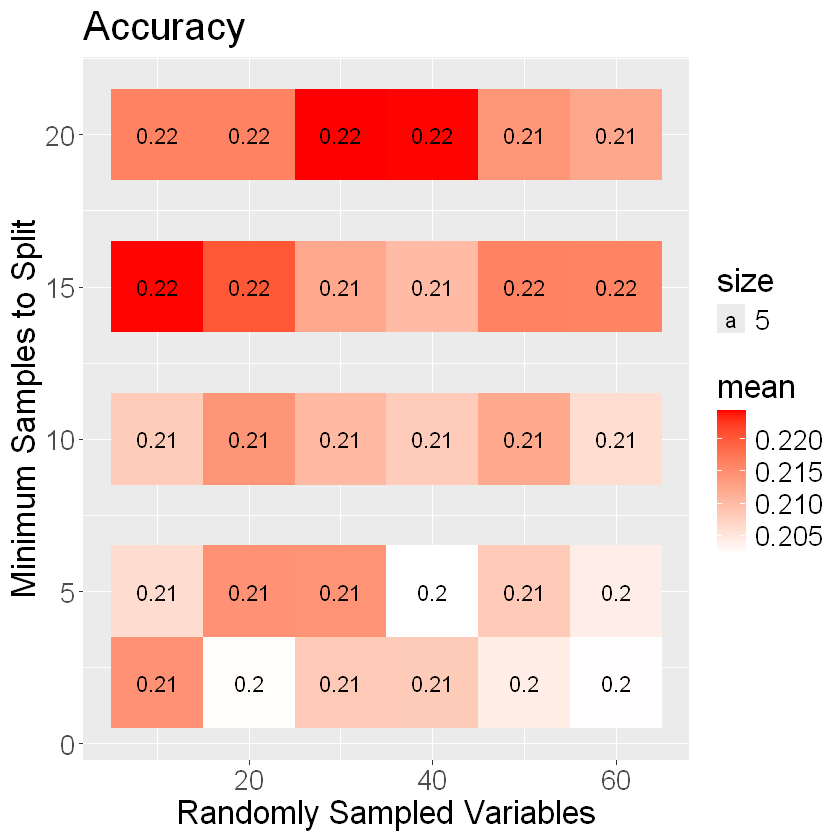

In [10]:
# plot accuracies of all values of hyperparameters

ggplot(model_tuning_accuracies %>% filter(.metric == "accuracy")) +
    geom_tile(aes(x=mtry, y=min_n, fill=mean)) +
    geom_text(aes(x=mtry, y=min_n, label=round(mean, 2), size=5)) +
    labs(x = "Randomly Sampled Variables", y = "Minimum Samples to Split", color="Estimated Accuracy", title="Accuracy") +
    theme(text = element_text(size=20)) +
    scale_fill_gradient(low="white", high="red")

# Print best hyperparameter values
best_params <- model_tuning_accuracies %>% arrange(desc(mean)) %>% head(1) %>% pull(mtry, min_n)
print("Best hyperparameters: (mtry, min_n)")
print(best_params)

Ignoring unknown labels:
• colour : "Estimated Recall"


[1] "Best hyperparameters:"
20 
30 


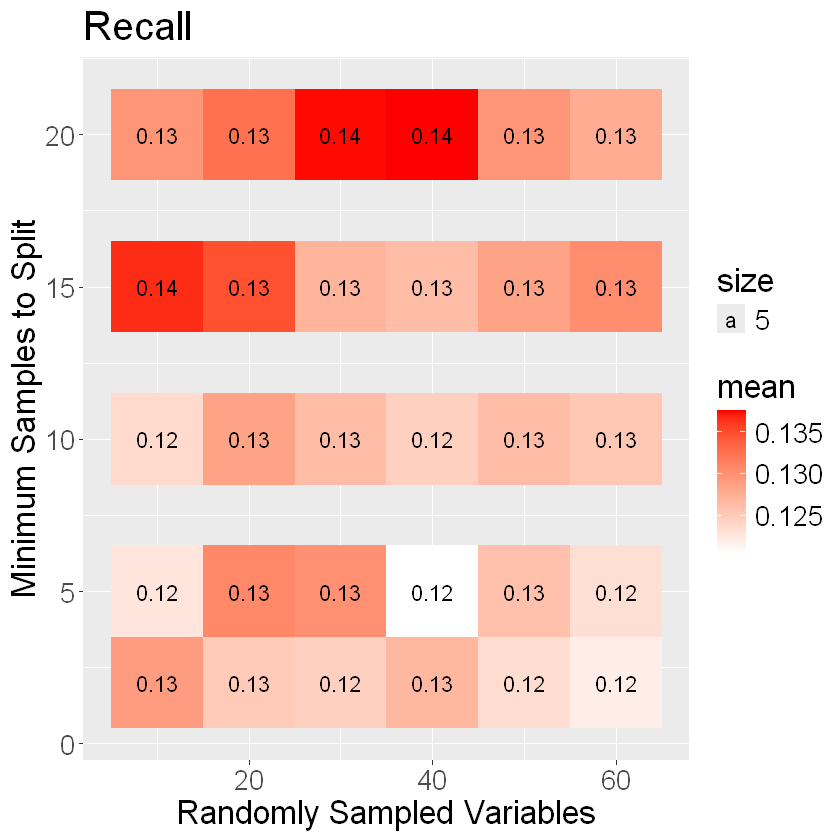

In [11]:
# plot accuracies of all values of hyperparameters

ggplot(model_tuning_accuracies %>% filter(.metric == "recall")) +
    geom_tile(aes(x=mtry, y=min_n, fill=mean)) +
    geom_text(aes(x=mtry, y=min_n, label=round(mean, 2), size=5)) +
    labs(x = "Randomly Sampled Variables", y = "Minimum Samples to Split", color="Estimated Recall", title="Recall") +
    theme(text = element_text(size=20)) +
    scale_fill_gradient(low="white", high="red")

# Print best hyperparameter values
best_params <- model_tuning_accuracies %>% arrange(desc(mean)) %>% head(1) %>% pull(mtry, min_n)
print("Best hyperparameters:")
print(best_params)

In [12]:
# retrain model on best parameters
best_params <- model_tuning %>%
  select_best()
print("Best Parameters:")
print(best_params)

model <- workflow() %>%
    add_recipe(recipe) %>%
    add_model(model_tuning_spec) %>%
    finalize_workflow(best_params) %>%
    # fit_resamples(resamples = train_vfold) # for v-fold cross validation
    fit(data = train_data) # to train on whole train set with no validation set

model

Warning message in select_best(.):
"No value of `metric` was given; "accuracy" will be used."


[1] "Best Parameters:"
# A tibble: 1 × 3
   mtry min_n .config         
  <dbl> <dbl> <chr>           
1    30    20 pre0_mod15_post0


Warning message:
"Dropped unused factor level(s) in dependent variable: 118."


══ Workflow [trained] ══════════════════════════════════════════════════════════
Preprocessor: Recipe
Model: rand_forest()

── Preprocessor ────────────────────────────────────────────────────────────────
0 Recipe Steps

── Model ───────────────────────────────────────────────────────────────────────
Ranger result

Call:
 ranger::ranger(x = maybe_data_frame(x), y = y, mtry = min_cols(~30,      x), num.trees = ~1000, min.node.size = min_rows(~20, x),      importance = ~"impurity", num.threads = 1, verbose = FALSE,      seed = sample.int(10^5, 1), probability = TRUE) 

Type:                             Probability estimation 
Number of trees:                  1000 
Sample size:                      494 
Number of independent variables:  66 
Mtry:                             30 
Target node size:                 20 
Variable importance mode:         impurity 
Splitrule:                        gini 
OOB prediction error (Brier s.):  0.7342578 

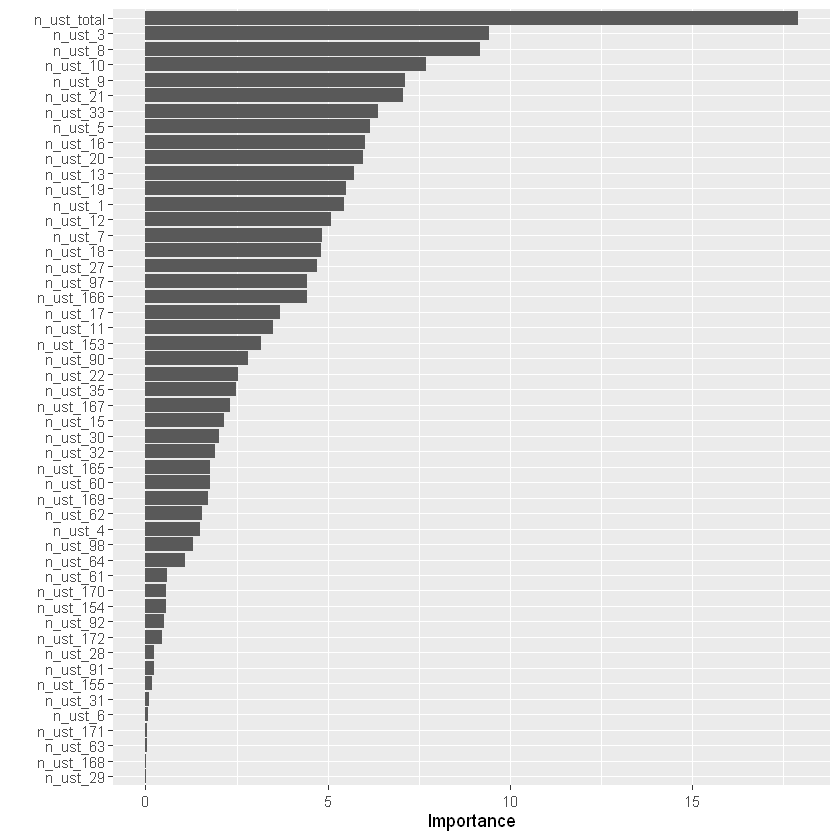

In [13]:
model %>% extract_fit_engine() %>% vip(num_features=50)

In [14]:
# Predict on the test set, and create a new DataFrame with inputs and outputs
test_predictions <- model %>% predict(test_data) %>%
    bind_cols(test_data)

In [15]:
# test_predictions

In [16]:
# What was the accuracy, precision, and recall of our model?
test_predictions %>% metrics(truth = UST, estimate = .pred_class)
test_predictions %>% precision(truth = UST, estimate = .pred_class, event_level = "second") # Precision = correct positive predictions / total positive predictions
test_predictions %>% recall(truth = UST, estimate = .pred_class, event_level = "second") # Recall = correct positive predictions / total positive test set observations

.metric,.estimator,.estimate
<chr>,<chr>,<dbl>
accuracy,multiclass,0.2372093
kap,multiclass,0.1376021


Warning message:
"While computing multiclass `precision()`, some levels had no predicted events
(i.e. `true_positive + false_positive = 0`).
Precision is undefined in this case, and those levels will be removed from the
averaged result.
Note that the following number of true events actually occurred for each
problematic event level:
'0': 2, '12': 0, '16': 1, '20': 3, '115': 0, '116': 2, '117': 4, '118': 1,
'119': 0"


.metric,.estimator,.estimate
<chr>,<chr>,<dbl>
precision,macro,0.3152648


Warning message:
"While computing multiclass `recall()`, some levels had no true events (i.e.
`true_positive + false_negative = 0`).
Recall is undefined in this case, and those levels will be removed from the
averaged result.
Note that the following number of predicted events actually occurred for each
problematic event level:
'12': 0, '115': 0, '119': 0, '120': 1"


.metric,.estimator,.estimate
<chr>,<chr>,<dbl>
recall,macro,0.1528953


In [17]:
# test_predictions %>% pull(does_it_match) %>% levels()
confusion_matrix <- test_predictions %>%
    conf_mat(truth = UST, estimate = .pred_class)
confusion_matrix

          Truth
Prediction  0  3  5  8  9 10 12 13 16 17 20 21 29 115 116 117 118 119 120
       0    0  0  0  0  0  0  0  0  0  0  0  0  0   0   0   0   0   0   0
       3    0  9  0  3  4  4  0  0  0  4  1  2  4   0   0   3   0   0   0
       5    0  0  5  0  0  0  0  1  1  1  0  0  1   0   0   0   0   0   0
       8    1  6  0  7  7  2  0  2  0  1  1  0  4   0   0   1   0   0   0
       9    0  7  3  7 10  2  0  2  0  2  0  5  2   0   0   0   0   0   0
       10   0  0  3  4  4  8  0  2  0  5  1  6  7   0   1   0   1   0   0
       12   0  0  0  0  0  0  0  0  0  0  0  0  0   0   0   0   0   0   0
       13   0  2  0  2  2  1  0  3  0  0  0  4  6   0   1   0   0   0   0
       16   0  0  0  0  0  0  0  0  0  0  0  0  0   0   0   0   0   0   0
       17   0  0  0  0  0  0  0  0  0  1  0  0  0   0   0   0   0   0   0
       20   0  0  0  0  0  0  0  0  0  0  0  0  0   0   0   0   0   0   0
       21   0  1  1  1  1  1  0  1  0  0  0  4  1   0   0   0   0   0   0
       29   1  3  1  5